<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Visualization**


Estimated time needed: **45** minutes


In this lab, you will focus on data visualization. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


After completing this lab, you will be able to:


-   Visualize the distribution of data.

-   Visualize the relationship between two features.

-   Visualize composition and comparison of data.




## Demo: How to work with database


Download the database file.


In [1]:
!wget https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv     100%[===================>] 152.13M  3.11MB/s    in 72s     
2026-10-11 22:15:19 (2.11 MB/s) - ‘survey-data.csv’ saved [159525875/159525875]


**Install and Import Necessary Python Libraries**

Ensure that you have the required libraries installed to work with SQLite and Pandas:


In [2]:
!pip install pandas 
!pip install matplotlib

import pandas as pd
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 65.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 131.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 67.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 64.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]


**Read the CSV File into a Pandas DataFrame**

Load the Stack Overflow survey data into a Pandas DataFrame:


In [3]:
# Read the CSV file
df = pd.read_csv('survey-data.csv')

# Display the first few rows of the data
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


**Create a SQLite Database and Insert the Data**

Now, let's create a new SQLite database (`survey-data.sqlite`) and insert the data from the DataFrame into a table using the sqlite3 library:


In [4]:
import sqlite3

# Create a connection to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Write the dataframe to the SQLite database
df.to_sql('main', conn, if_exists='replace', index=False)


# Close the connection
conn.close()


**Verify the Data in the SQLite Database**
Verify that the data has been correctly inserted into the SQLite database by running a simple query:


In [5]:
# Reconnect to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Run a simple query to check the data
QUERY = "SELECT * FROM main LIMIT 5"
df_check = pd.read_sql_query(QUERY, conn)

# Display the results
print(df_check)


   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

## Demo: Running an SQL Query


Count the number of rows in the table named 'main'


In [6]:
QUERY = """
SELECT COUNT(*) 
FROM main
"""
df = pd.read_sql_query(QUERY, conn)
df.head()


,COUNT(*)
0,65437


## Demo: Listing All Tables


To view the names of all tables in the database:


In [7]:
QUERY = """
SELECT name as Table_Name FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


## Demo: Running a Group By Query
    
For example, you can group data by a specific column, like Age, to get the count of respondents in each age group:


In [8]:
QUERY = """
SELECT Age, COUNT(*) as count
FROM main
GROUP BY Age
ORDER BY Age
"""
pd.read_sql_query(QUERY, conn)


,Age,count
0,18-24 years old,14098
1,25-34 years old,23911
2,35-44 years old,14942
3,45-54 years old,6249
4,55-64 years old,2575
5,65 years or older,772
6,Prefer not to say,322
7,Under 18 years old,2568


## Demo: Describing a table

Use this query to get the schema of a specific table, main in this case:


In [9]:
table_name = 'main'

QUERY = """
SELECT sql FROM sqlite_master 
WHERE name= '{}'
""".format(table_name)

df = pd.read_sql_query(QUERY, conn)
print(df.iat[0,0])


CREATE TABLE "main" (
"ResponseId" INTEGER,
  "MainBranch" TEXT,
  "Age" TEXT,
  "Employment" TEXT,
  "RemoteWork" TEXT,
  "Check" TEXT,
  "CodingActivities" TEXT,
  "EdLevel" TEXT,
  "LearnCode" TEXT,
  "LearnCodeOnline" TEXT,
  "TechDoc" TEXT,
  "YearsCode" TEXT,
  "YearsCodePro" TEXT,
  "DevType" TEXT,
  "OrgSize" TEXT,
  "PurchaseInfluence" TEXT,
  "BuyNewTool" TEXT,
  "BuildvsBuy" TEXT,
  "TechEndorse" TEXT,
  "Country" TEXT,
  "Currency" TEXT,
  "CompTotal" REAL,
  "LanguageHaveWorkedWith" TEXT,
  "LanguageWantToWorkWith" TEXT,
  "LanguageAdmired" TEXT,
  "DatabaseHaveWorkedWith" TEXT,
  "DatabaseWantToWorkWith" TEXT,
  "DatabaseAdmired" TEXT,
  "PlatformHaveWorkedWith" TEXT,
  "PlatformWantToWorkWith" TEXT,
  "PlatformAdmired" TEXT,
  "WebframeHaveWorkedWith" TEXT,
  "WebframeWantToWorkWith" TEXT,
  "WebframeAdmired" TEXT,
  "EmbeddedHaveWorkedWith" TEXT,
  "EmbeddedWantToWorkWith" TEXT,
  "EmbeddedAdmired" TEXT,
  "MiscTechHaveWorkedWith" TEXT,
  "MiscTechWantToWorkWith" TEXT,


## Hands-on Lab


### Visualizing the Distribution of Data

**Histograms**

Plot a histogram of CompTotal (Total Compensation).


count     3.374000e+04
mean     2.963841e+145
std      5.444117e+147
min       0.000000e+00
25%       6.000000e+04
50%       1.100000e+05
75%       2.500000e+05
max      1.000000e+150
Name: CompTotal, dtype: float64

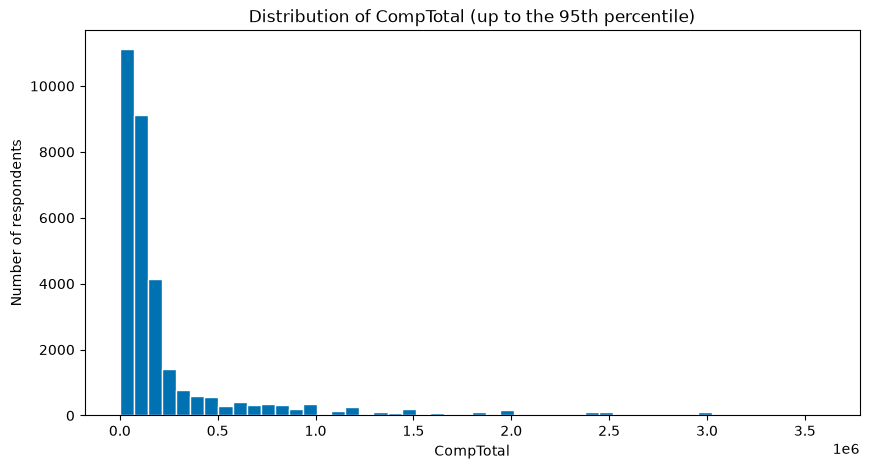

In [10]:
## Write your code here

QUERY = "SELECT CompTotal FROM main WHERE CompTotal IS NOT NULL"
df_comp = pd.read_sql_query(QUERY, conn)
print(df_comp["CompTotal"].describe())

# CompTotal has extreme values, so cap the view at the 95th percentile to make the histogram readable
cap = df_comp["CompTotal"].quantile(0.95)
plt.figure(figsize=(10, 5))
plt.hist(df_comp.loc[df_comp["CompTotal"] <= cap, "CompTotal"], bins=50, color="#0072B2", edgecolor="white")
plt.title("Distribution of CompTotal (up to the 95th percentile)")
plt.xlabel("CompTotal")
plt.ylabel("Number of respondents")
plt.show()

**Box Plots**

Plot a box plot of Age.


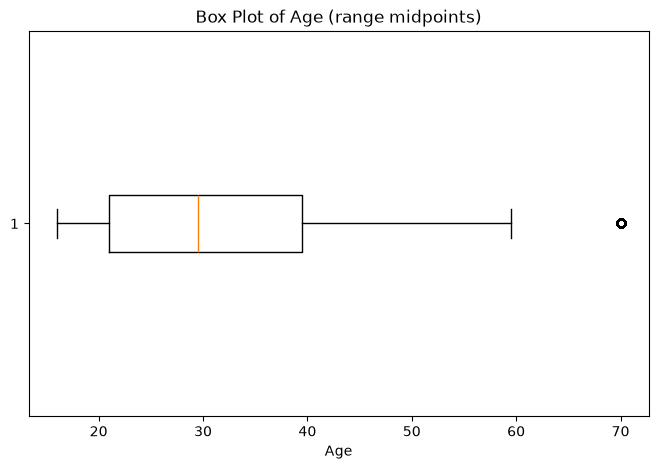

In [11]:
## Write your code here
age_map = {
    "Under 18 years old": 16,
    "18-24 years old": 21,
    "25-34 years old": 29.5,
    "35-44 years old": 39.5,
    "45-54 years old": 49.5,
    "55-64 years old": 59.5,
    "65 years or older": 70,
}

df_age = pd.read_sql_query("SELECT Age FROM main", conn)
df_age["Age_numeric"] = df_age["Age"].map(age_map)  # "Prefer not to say" becomes NaN

plt.figure(figsize=(8, 5))
plt.boxplot(df_age["Age_numeric"].dropna(), orientation="horizontal")
plt.title("Box Plot of Age (range midpoints)")
plt.xlabel("Age")
plt.show()

### Visualizing Relationships in Data

**Scatter Plots**

Create a scatter plot of Age and WorkExp.


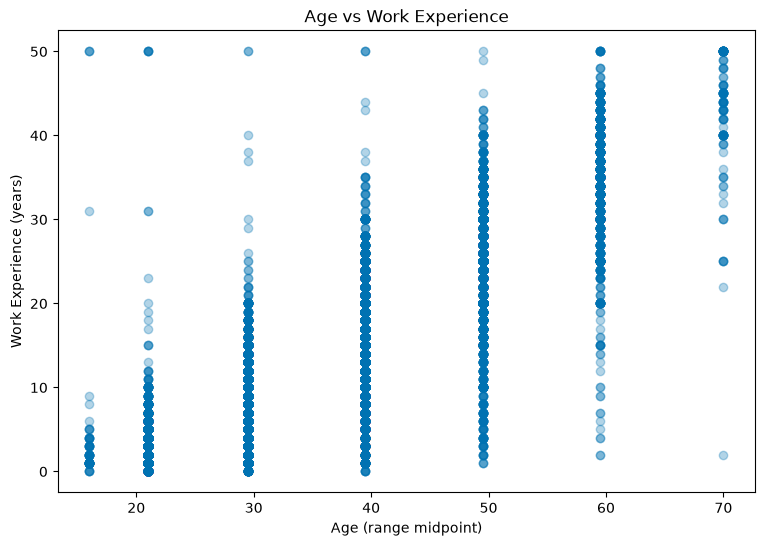

In [12]:
## Write your code here
df_sc = pd.read_sql_query("SELECT Age, WorkExp FROM main", conn)
df_sc["Age_numeric"] = df_sc["Age"].map(age_map)   # age_map from the previous cell

plt.figure(figsize=(9, 6))
plt.scatter(df_sc["Age_numeric"], df_sc["WorkExp"], alpha=0.3, color="#0072B2")
plt.title("Age vs Work Experience")
plt.xlabel("Age (range midpoint)")
plt.ylabel("Work Experience (years)")
plt.show()

**Bubble Plots**

Create a bubble plot of `TimeSearching` and `Frustration` using the Age column as the bubble size.


Age              str
TimeSearching    str
Frustration      str
dtype: object
TimeSearching
NaN                           36526
30-60 minutes a day           10951
15-30 minutes a day            7805
60-120 minutes a day           5275
Less than 15 minutes a day     2689
Over 120 minutes a day         2191
Name: count, dtype: int64
Frustration
NaN                                                                                                    37186
None of these                                                                                           2364
Amount of technical debt                                                                                2067
Amount of technical debt;Reliability of tools/systems used in work                                       831
Amount of technical debt;Complexity of tech stack for deployment;Complexity of tech stack for build      666
Amount of technical debt;Tracking my work                                                                556
A

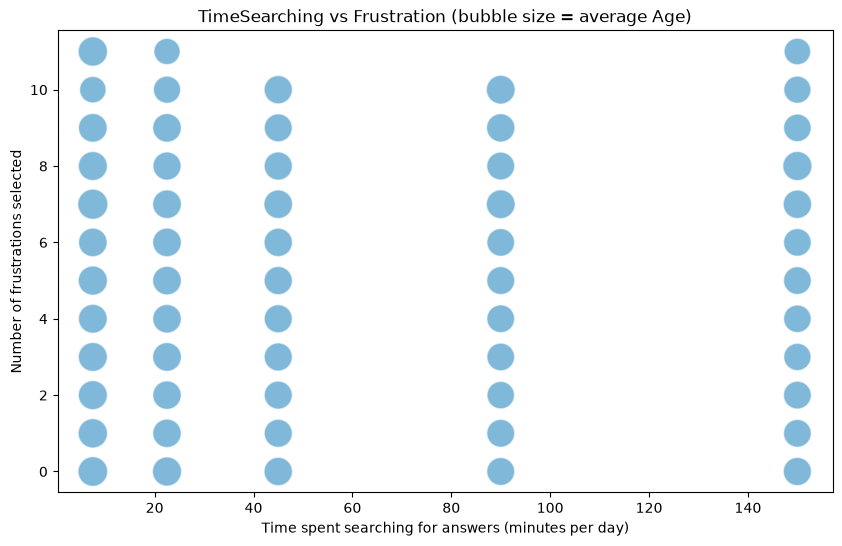

In [14]:
## Write your code here
df_bub = pd.read_sql_query("SELECT Age, TimeSearching, Frustration FROM main", conn)
print(df_bub.dtypes)
print(df_bub["TimeSearching"].value_counts(dropna=False).head(10))
print(df_bub["Frustration"].value_counts(dropna=False).head(10))
time_map = {
    "Less than 15 minutes a day": 7.5,
    "15-30 minutes a day": 22.5,
    "30-60 minutes a day": 45,
    "60-120 minutes a day": 90,
    "Over 120 minutes a day": 150,
}

df_bub = pd.read_sql_query("SELECT Age, TimeSearching, Frustration FROM main", conn)
df_bub = df_bub.dropna(subset=["Age", "TimeSearching", "Frustration"]).copy()

df_bub["Age_numeric"] = df_bub["Age"].map(age_map)
df_bub["TimeSearching_min"] = df_bub["TimeSearching"].map(time_map)
df_bub["Frustration_count"] = df_bub["Frustration"].apply(
    lambda x: 0 if x == "None of these" else len(x.split(";"))
)
df_bub = df_bub.dropna(subset=["Age_numeric", "TimeSearching_min"])

# One bubble per (time searching, number of frustrations) pair; bubble size = average age of that group
bubble = (df_bub.groupby(["TimeSearching_min", "Frustration_count"])
                .agg(avg_age=("Age_numeric", "mean"), respondents=("Age_numeric", "size"))
                .reset_index())
print(bubble.head(10))

plt.figure(figsize=(10, 6))
plt.scatter(bubble["TimeSearching_min"], bubble["Frustration_count"],
            s=bubble["avg_age"] * 12, alpha=0.5, color="#0072B2", edgecolor="white")
plt.title("TimeSearching vs Frustration (bubble size = average Age)")
plt.xlabel("Time spent searching for answers (minutes per day)")
plt.ylabel("Number of frustrations selected")
plt.show()

### Visualizing Composition of Data

**Pie Charts**

Create a pie chart of the top 5 databases(`DatabaseWantToWorkWith`) that respondents wish to learn next year.


DatabaseWantToWorkWith
PostgreSQL    24005
SQLite        13489
MySQL         12269
MongoDB       10982
Redis         10847
Name: count, dtype: int64

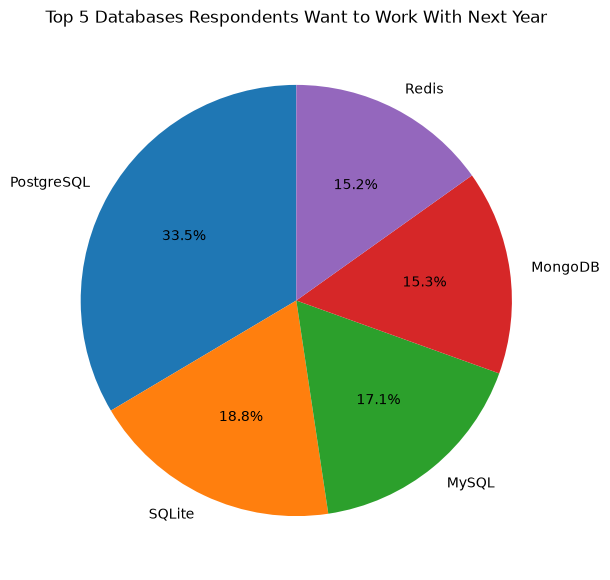

In [15]:
## Write your code here
df_db = pd.read_sql_query("SELECT DatabaseWantToWorkWith FROM main WHERE DatabaseWantToWorkWith IS NOT NULL", conn)

db_counts = (df_db["DatabaseWantToWorkWith"].str.split(";").explode().str.strip().value_counts())
top5 = db_counts.head(5)
print(top5)

plt.figure(figsize=(7, 7))
plt.pie(top5.values, labels=top5.index, autopct="%1.1f%%", startangle=90)
plt.title("Top 5 Databases Respondents Want to Work With Next Year")
plt.show()

**Stacked Charts** 

Create a stacked bar chart of median `TimeSearching` and `TimeAnswering` for the age group 30 to 35.


TimeAnswering
NaN                           11350
15-30 minutes a day            4226
30-60 minutes a day            3833
Less than 15 minutes a day     2510
60-120 minutes a day           1534
Over 120 minutes a day          458
Name: count, dtype: int64
Median TimeSearching: 45.0 | Median TimeAnswering: 22.5

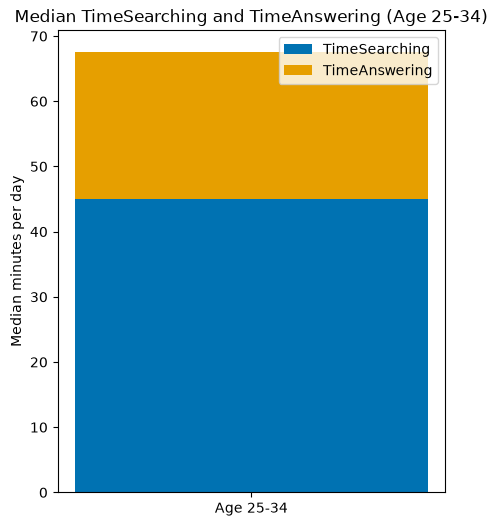

In [16]:
## Write your code here
time_map = {
    "Less than 15 minutes a day": 7.5,
    "15-30 minutes a day": 22.5,
    "30-60 minutes a day": 45,
    "60-120 minutes a day": 90,
    "Over 120 minutes a day": 150,
}

df_t = pd.read_sql_query(
    "SELECT Age, TimeSearching, TimeAnswering FROM main WHERE Age = '25-34 years old'", conn)
print(df_t["TimeAnswering"].value_counts(dropna=False))   # check the values match time_map

df_t["Search_min"] = df_t["TimeSearching"].map(time_map)
df_t["Answer_min"] = df_t["TimeAnswering"].map(time_map)

med_search = df_t["Search_min"].median()
med_answer = df_t["Answer_min"].median()
print("Median TimeSearching:", med_search, "| Median TimeAnswering:", med_answer)

plt.figure(figsize=(5, 6))
plt.bar(["Age 25-34"], [med_search], label="TimeSearching", color="#0072B2")
plt.bar(["Age 25-34"], [med_answer], bottom=[med_search], label="TimeAnswering", color="#E69F00")
plt.ylabel("Median minutes per day")
plt.title("Median TimeSearching and TimeAnswering (Age 25-34)")
plt.legend()
plt.show()

### Visualizing Comparison of Data

**Line Chart**

Plot the median `CompTotal` for all ages from 45 to 60.


Age
45-54 years old    130000.0
55-64 years old    135000.0
Name: CompTotal, dtype: float64

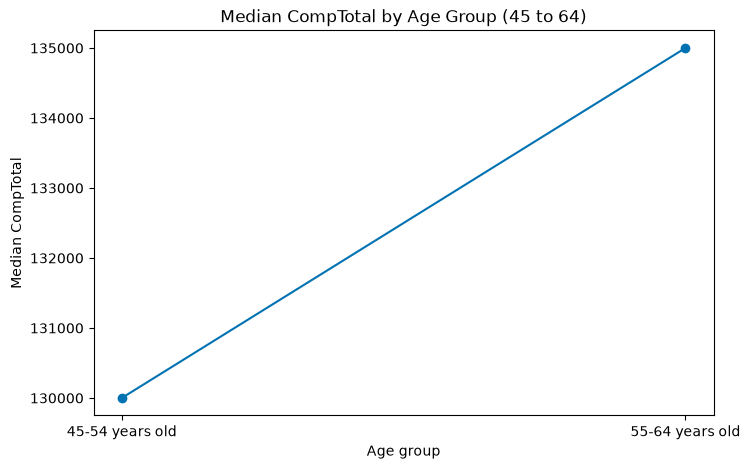

In [17]:
## Write your code here
age_order = ["45-54 years old", "55-64 years old"]

df_line = pd.read_sql_query(
    "SELECT Age, CompTotal FROM main WHERE CompTotal IS NOT NULL AND Age IN ('45-54 years old', '55-64 years old')",
    conn)

median_comp = df_line.groupby("Age")["CompTotal"].median().reindex(age_order)
print(median_comp)

plt.figure(figsize=(8, 5))
plt.plot(median_comp.index, median_comp.values, marker="o", color="#0072B2")
plt.title("Median CompTotal by Age Group (45 to 64)")
plt.xlabel("Age group")
plt.ylabel("Median CompTotal")
plt.show()

**Bar Chart**

Create a horizontal bar chart using the `MainBranch` column.


MainBranch
I am a developer by profession                                                           50207
I am not primarily a developer, but I write code sometimes as part of my work/studies     6511
I am learning to code                                                                     3875
I code primarily as a hobby                                                               3334
I used to be a developer by profession, but no longer am                                  1510
Name: count, dtype: int64

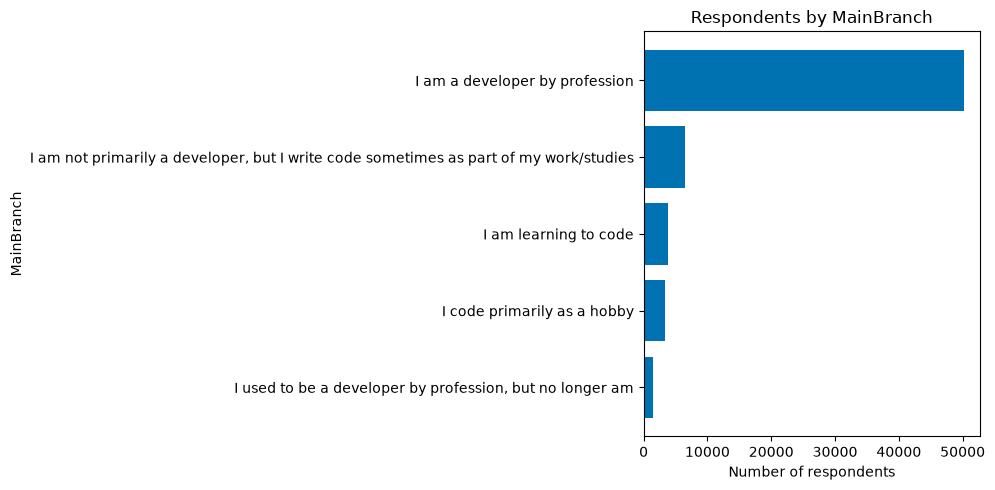

In [18]:
## Write your code here
df_mb = pd.read_sql_query("SELECT MainBranch FROM main WHERE MainBranch IS NOT NULL", conn)
mb_counts = df_mb["MainBranch"].value_counts()
print(mb_counts)

plt.figure(figsize=(10, 5))
plt.barh(mb_counts.index[::-1], mb_counts.values[::-1], color="#0072B2")
plt.title("Respondents by MainBranch")
plt.xlabel("Number of respondents")
plt.ylabel("MainBranch")
plt.tight_layout()
plt.show()

### Summary


In this lab, you focused on extracting and visualizing data from an RDBMS using SQL queries and SQLite. You applied various visualization techniques, including:

- Histograms to display the distribution of CompTotal.
- Box plots to show the spread of ages.
- Scatter plots and bubble plots to explore relationships between variables like Age, WorkExp, `TimeSearching` and `TimeAnswering`.
- Pie charts and stacked charts to visualize the composition of data.
- Line charts and bar charts to compare data across categories.


### Close the Database Connection

Once the lab is complete, ensure to close the database connection:


In [19]:
conn.close()

## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
